# Estresse no trabalho por setor: análise

**Dados sintéticos.** Este caderno mostra a análise passo a passo. Toda a lógica está em `src/jss/` e é coberta por testes; aqui só chamamos as funções e olhamos os resultados. O método está em `docs/METODO.md`.

In [1]:
import sys
sys.path.insert(0, 'src')

import pandas as pd
from IPython.display import Image, display

from jss import analise, graficos, pontuacao

pd.options.display.float_format = '{:.2f}'.format
dados = pd.read_csv('data/limpo/respostas_limpas.csv', dtype=str)
dados.shape

(130, 19)

## 1. Escores por dimensão

Cada resposta vira 1 a 4 pontos (`q04` e `q09` invertidos) e cada dimensão é a soma dos seus itens.

In [2]:
escores = pontuacao.calcular_escores(dados)
escores[['demanda', 'controle', 'apoio']].describe()

,demanda,controle,apoio
count,130.00,129.00,130.00
mean,15.35,16.02,19.55
std,3.39,4.64,3.63
min,6.00,6.00,10.00
25%,13.00,13.00,17.00
50%,16.00,16.00,20.00
75%,18.00,20.00,23.00
max,20.00,24.00,24.00


## 2. Consistência interna (alfa de Cronbach)

In [3]:
analise.tabela_de_alfas(dados)

,dimensao,itens,n,alfa
0,demanda,5,130,0.81
1,controle,6,129,0.87
2,apoio,6,130,0.80
3,controle: discernimento,4,129,0.81
4,controle: autoridade,2,130,0.77


## 3. Quadrantes do modelo demanda-controle e apoio social

Corte: mediana de todos os respondentes. "Alto" é estar acima da mediana.

In [4]:
cortes = analise.calcular_cortes(escores)
classificado = analise.classificar(escores, cortes)
print(cortes)
analise.quadrantes_por_grupo(classificado, ['unidade'])

{'demanda': 16.0, 'controle': 16.0, 'apoio': 20.0}


quadrante,Alta exigência,Trabalho ativo,Trabalho passivo,Baixa exigência
unidade,,,,
Unidade 1,15,17,22,26
Unidade 2,19,8,13,9


In [5]:
pd.crosstab(classificado['unidade'], classificado['apoio_nivel'])

apoio_nivel,Alto apoio,Baixo apoio
unidade,,
Unidade 1,32,48
Unidade 2,31,19


## 4. Descritivo por unidade e por setor

In [6]:
analise.descritivo(classificado, ['unidade'])

,unidade,n,demanda_media,demanda_dp,demanda_mediana,controle_media,controle_dp,controle_mediana,apoio_media,apoio_dp,apoio_mediana,pct_alta_exigencia,pct_baixo_apoio
0,Unidade 1,80,14.99,3.47,15.00,17.29,4.27,17.50,19.18,3.50,19.00,18.75,60.00
1,Unidade 2,50,15.92,3.19,17.00,13.96,4.52,15.00,20.16,3.79,21.00,38.78,38.00


In [7]:
por_setor = analise.descritivo(classificado, ['unidade', 'setor'])
por_setor[['unidade', 'setor', 'n', 'demanda_media', 'controle_media', 'apoio_media', 'pct_alta_exigencia', 'pct_baixo_apoio']]

,unidade,setor,n,demanda_media,controle_media,apoio_media,pct_alta_exigencia,pct_baixo_apoio
0,Unidade 1,Administrativo,6,11.33,18.83,20.00,16.67,66.67
1,Unidade 1,Logística,12,15.17,18.00,19.83,25.00,41.67
2,Unidade 1,Manutenção,18,15.61,18.72,19.17,5.56,55.56
3,Unidade 1,Outros,5,14.60,18.80,18.00,0.00,80.00
4,Unidade 1,Produção,30,15.43,15.37,18.80,30.00,66.67
5,Unidade 1,Qualidade,9,14.67,18.00,19.67,11.11,55.56
6,Unidade 2,Expedição,8,15.88,13.25,18.88,62.50,62.50
7,Unidade 2,Manutenção,10,14.90,16.50,20.50,10.00,30.00
8,Unidade 2,Outros,5,15.80,17.80,22.00,20.00,20.00
9,Unidade 2,Produção,27,16.33,12.46,20.07,46.15,37.04


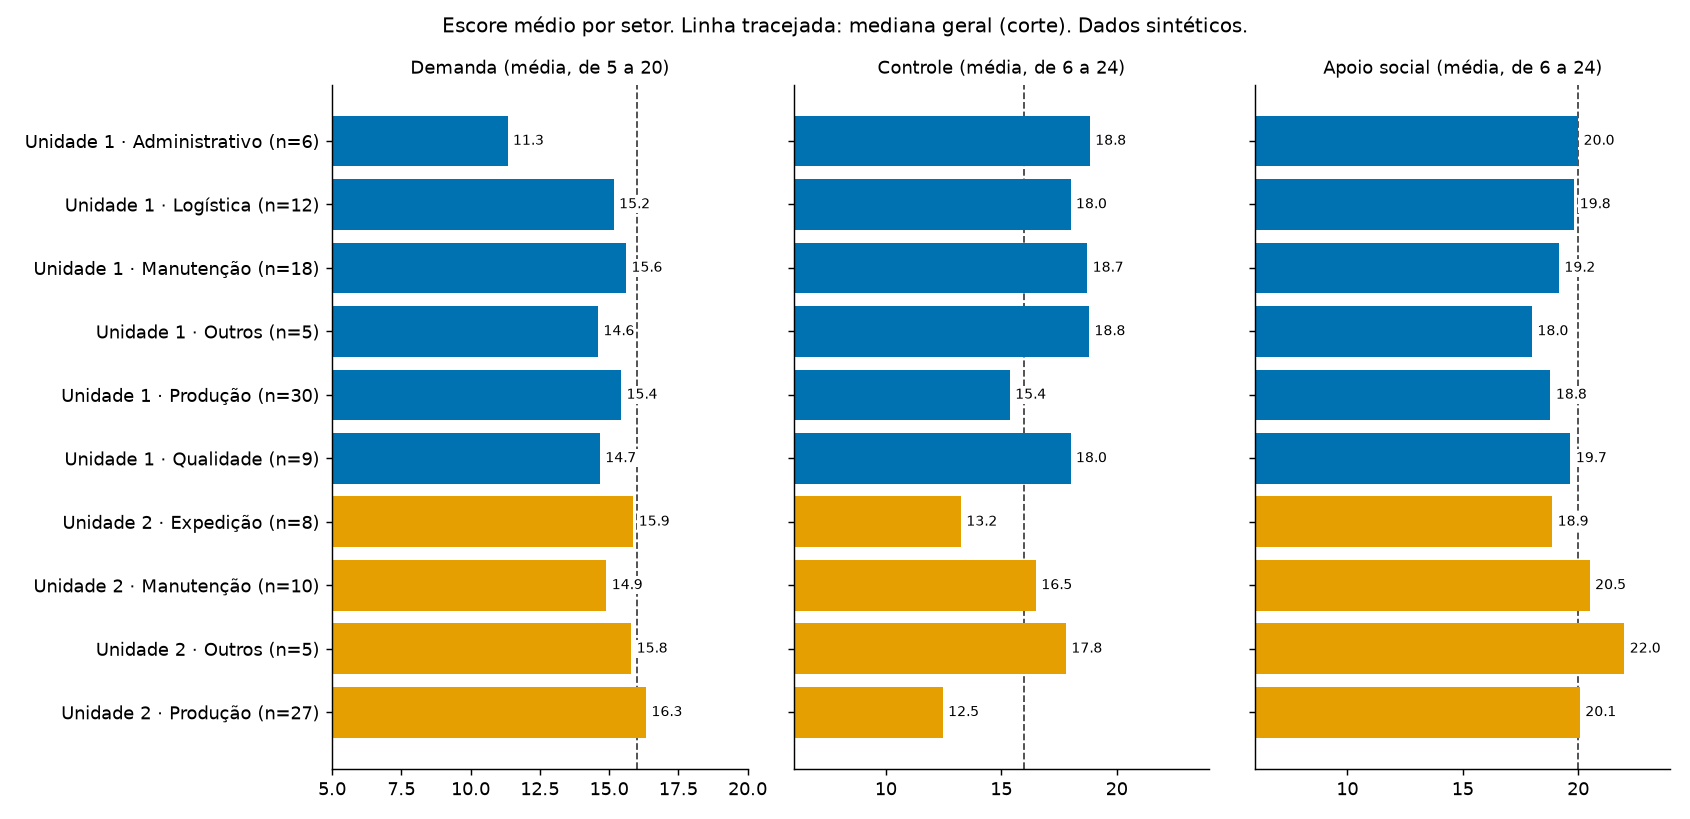

In [8]:
graficos.escores_por_setor(por_setor, cortes, 'resultados/figuras/escores_por_setor.png', ' Dados sintéticos.')
display(Image('resultados/figuras/escores_por_setor.png'))

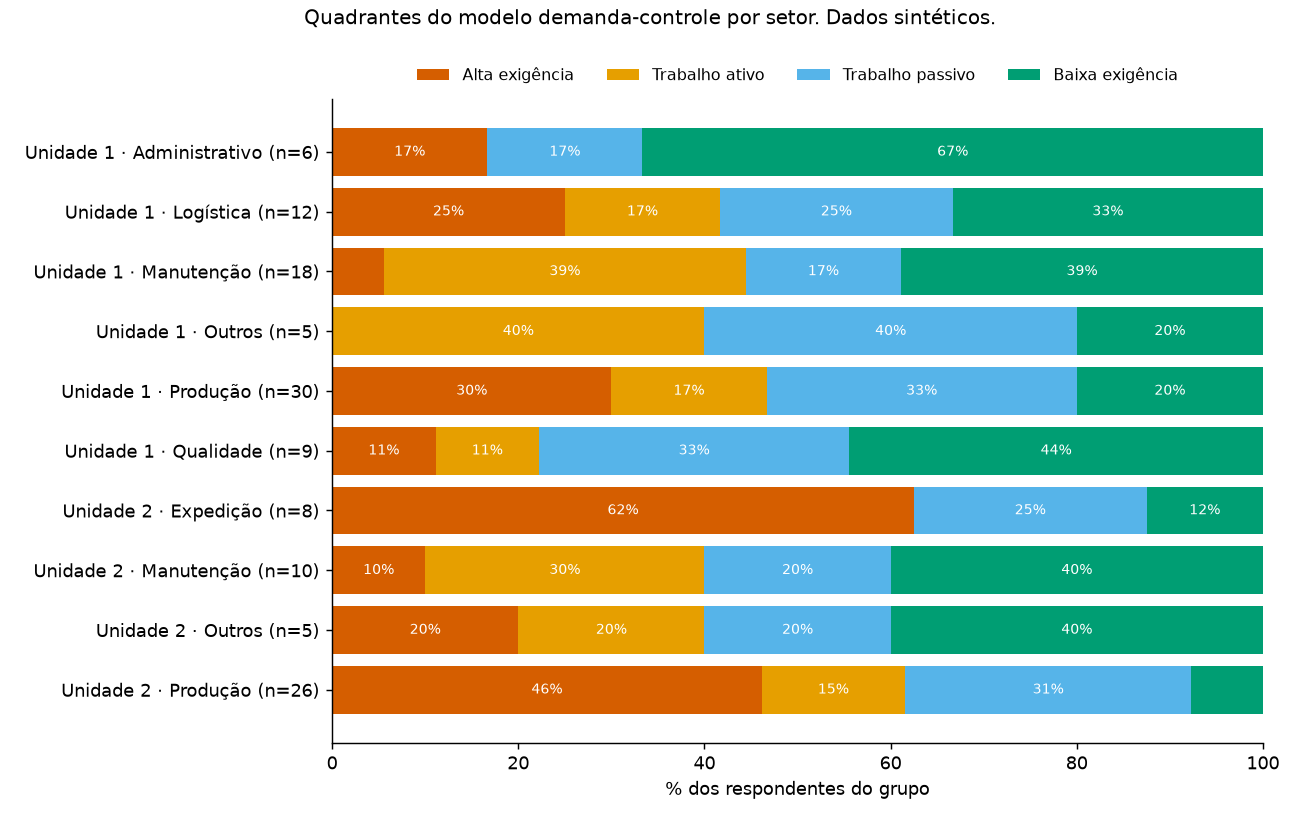

In [9]:
graficos.quadrantes_por_setor(analise.quadrantes_por_grupo(classificado, ['unidade', 'setor']), 'resultados/figuras/quadrantes_por_setor.png', ' Dados sintéticos.')
display(Image('resultados/figuras/quadrantes_por_setor.png'))

## 5. Comparação entre as unidades

Teste de Mann-Whitney (não paramétrico) e correlação bisserial por postos como tamanho de efeito (positivo = escores maiores na Unidade 1).

**Ressalva:** com 80 e 50 respondentes, o teste só detecta diferenças de tamanho médio para cima. Um p alto não prova que as unidades são iguais, e três testes seguidos aumentam a chance de um falso positivo.

In [10]:
analise.comparar_unidades(escores)

,dimensao,n_unidade_1,n_unidade_2,mediana_unidade_1,mediana_unidade_2,U,p,efeito_r
0,demanda,80,50,15.00,17.00,1679.00,0.12,-0.16
1,controle,80,49,17.50,15.00,2715.50,0.00,0.39
2,apoio,80,50,19.00,21.00,1613.00,0.06,-0.19
